In [1]:
import pandas as pd

# Load Data

In [ ]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [ ]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,5,79,58,128,93,12,0,0,18,...,3,0,1,2,9,16,22,21,0,1
1,ENSG00000000460,8,10,21,14,6,8,25,42,5,...,0,3,0,2,63,3,3,0,1,0
2,ENSG00000000938,24,336,334,59,120,22,31,13,19,...,8,45,1,7,163,90,46,75,14,8
3,ENSG00000001036,38,46,15,36,25,43,27,27,59,...,1,3,4,15,3,6,10,8,3,0
4,ENSG00000001461,72,17,11,9,18,28,5,6,49,...,1,1,0,0,12,2,6,6,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,349,133,99,87,171,260,232,204,188,...,0,0,0,5,0,2,18,31,22,23
5436,ENSG00000272053,980,658,294,265,818,2066,1579,1161,2003,...,18,17,17,107,41,52,78,203,12,16
5437,ENSG00000272168,51,20,11,31,65,49,56,25,131,...,0,0,0,26,0,1,15,6,10,0
5438,ENSG00000272369,29,41,24,3,51,33,26,52,35,...,0,3,1,8,2,1,0,3,2,1


In [ ]:
import numpy as np

# Minimal TMM normalization adapted from edgeR logic
# Returns CPM and factors scaled so geometric mean of factors is 1.
def compute_tmm_cpm(counts_df, trim_M=0.3, trim_A=0.05, ref_sample=None):
    counts = counts_df.copy()
    lib_sizes = counts.sum(axis=0)

    # Pick reference sample: closest library size to median if none provided
    if ref_sample is None:
        ref_sample = (lib_sizes - lib_sizes.median()).abs().idxmin()
    ref_counts = counts[ref_sample]
    lib_ref = lib_sizes[ref_sample]

    factors = {}

    def tmm_factor(test_counts, lib_test):
        mask = (test_counts > 0) & (ref_counts > 0)
        if mask.sum() == 0:
            return 1.0

        test = test_counts[mask]
        ref = ref_counts[mask]

        logR = np.log2((test / lib_test) / (ref / lib_ref))
        logA = 0.5 * np.log2((test / lib_test) * (ref / lib_ref))
        weights = 1.0 / ((1.0 / test) + (1.0 / ref))

        # Trim extremes on M and A
        m_low, m_high = np.quantile(logR, [trim_M / 2, 1 - trim_M / 2])
        a_low, a_high = np.quantile(logA, [trim_A / 2, 1 - trim_A / 2])
        keep = (logR >= m_low) & (logR <= m_high) & (logA >= a_low) & (logA <= a_high)

        if keep.sum() == 0:
            return 1.0

        weighted_M = np.average(logR[keep], weights=weights[keep])
        return 2 ** weighted_M

    for col in counts.columns:
        factors[col] = tmm_factor(counts[col], lib_sizes[col])

    factors = pd.Series(factors)
    factors = factors / np.exp(np.log(factors).mean())  # rescale to geometric mean 1
    effective_lib_sizes = lib_sizes * factors

    cpm = counts.divide(effective_lib_sizes, axis=1) * 1_000_000
    return cpm, factors, effective_lib_sizes

In [ ]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

In [ ]:
data

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [ ]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [ ]:
data_transposed['cancer_type'].value_counts()

In [ ]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

In [ ]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [ ]:
data_transposed.reset_index(drop=True, inplace=True)


In [ ]:
data_transposed

In [ ]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_normalized = data_filtered.copy()

In [ ]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [ ]:
data_normalized

In [ ]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [ ]:
X

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [ ]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [ ]:
y.value_counts()

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
# y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:
# X_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv", index= False)
# X_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv", index= False)
# y_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_train.csv", index= False)
# y_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_test.csv", index= False)


In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

### Ranking all genes by RandomForest importance...

In [ ]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\feature_importance.csv', index=False)

In [ ]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

In [ ]:
X_test[all_features]

In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv', index=False)
X_test[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [58]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [59]:
X_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_train_rF_DEG_train_lung.csv",low_memory = False)
X_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_test_rF_DEG_train_lung.csv",low_memory = False)

y_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_train_rF_DEG_train.csv",low_memory = False)
y_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_test_rF_DEG_train.csv",low_memory = False)

In [60]:
import pandas as pd
import mygene

# 2. Extract the Ensembl IDs
# We filter for columns starting with 'ENSG' to avoid messing up index columns like 'Unnamed: 0'
ensembl_ids = [col for col in X_train.columns if col.startswith('ENSG')]

# (Optional) If your IDs have decimals like 'ENSG00000096060.1', you need to strip them:
# ensembl_ids = [col.split('.')[0] for col in ensembl_ids]

# 3. Query the MyGene Database
print("Querying MyGene.info for gene symbols...")
mg = mygene.MyGeneInfo()
results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human')

# 4. Create a mapping dictionary { 'ENSG_ID' : 'Gene_Symbol' }
id_to_symbol = {}
for res in results:
    query_id = res['query']
    
    # If a gene symbol is found, use it. Otherwise, keep the original Ensembl ID.
    if 'symbol' in res:
        id_to_symbol[query_id] = res['symbol']
    else:
        id_to_symbol[query_id] = query_id

# 5. Rename the columns in both DataFrames
X_train.rename(columns=id_to_symbol, inplace=True)
X_test.rename(columns=id_to_symbol, inplace=True)

print("Conversion complete!")
print("Preview of new columns in X_train:")
print(X_train.head())

Querying MyGene.info for gene symbols...


5 input query terms found no hit:	['ENSG00000197459', 'ENSG00000267243', 'ENSG00000136653', 'ENSG00000163386', 'ENSG00000148362']


Conversion complete!
Preview of new columns in X_train:
   WDR11-DT    MAGOHB   ZNF542P    IFITM3   HSD17B3     NOMO1   ITGB3BP  \
0  5.590922  4.920421  4.513914  6.808245  3.643703  5.229449  5.296728   
1  7.111388  6.283755  6.129917  4.970461  4.523772  7.441317  7.797965   
2  4.176511  3.782071  2.764579  7.538766  2.764579  3.782071  4.889779   
3  5.002632  4.644839  3.753215  5.804742  2.764579  4.836138  6.369995   
4  6.255441  5.619431  4.050363  7.027353  3.522978  4.234493  6.180337   

   LINC01088    COL6A3  ENSG00000260661  ...   CENATAC     LUC7L      DPP4  \
0   3.774722  5.391791         2.764579  ...  3.485998  4.452266  3.485998   
1   4.749558  3.944942         3.610526  ...  2.764579  3.944942  3.192072   
2   2.764579  4.889779         4.176511  ...  5.344660  6.186679  2.764579   
3   3.753215  4.137808         2.764579  ...  6.427103  7.613563  4.137808   
4   4.050363  5.435232         2.764579  ...  5.367917  5.435232  2.764579   

        LTF      PRCP   

In [61]:
# X_train = X_train.iloc[:,:300]
# 0.00055

In [62]:
# X_test = X_test.iloc[:,:300]

In [63]:
X_train = X_train.iloc[:,:208]
X_test = X_test.iloc[:,:208]
# cut at >= 0.00080 point

In [64]:
from sklearn.model_selection import StratifiedKFold

In [65]:
from xgboost import XGBClassifier

In [66]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [67]:
list_feature = list(X_train.columns)

In [68]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [69]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [70]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [71]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

In [72]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Categorical, Integer # Skopt uses specialized spaces
from sklearn.metrics import accuracy_score
import numpy as np

# Grid search

In [74]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

# --- 1. Custom Scorers ---
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0

specificity_scorer = make_scorer(recall_score, pos_label=0)

def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': specificity_scorer,
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) 
}

# --- 2. Main execution block ---
if __name__ == "__main__":
    
    # Calculate ratio: 391 / 1628 approx 0.24
    ratio = 391 / 522

    model = CatBoostClassifier(
        random_state=11,
        verbose=False,       # Prevents flooding the console with tree logs
        allow_writing_files=False, # CatBoost creates folders by default; this disables it
        scale_pos_weight=ratio
    )

    # --- Explain these Parameters ---
    params = {
        # iterations: Similar to n_estimators.
        'iterations': [500, 1000, 2000],
        # depth: Tree depth. CatBoost uses symmetric trees, usually 6 or 8 is best.
        'learning_rate': [0.01, 0.05, 0.1],
        # l2_leaf_reg: Regularization term. Higher values help if PCA shows overlap.
        'l2_leaf_reg': [1, 3, 5]
    }

    grid_search = GridSearchCV(
        estimator=model, 
        param_grid=params, 
        cv=5, 
        verbose=1, 
        scoring=scoring_metrics,
        refit='AUC', # Refit based on our Sn/Sp average
        return_train_score=True, 
        n_jobs=-1
    )

    result = []
    result2 = []

    # --- 3. The Feature Ranking Loop ---
    for i, rank in enumerate(ranks[61:], start=61):
        X_current = x_train_sc[:, :i+1]
        y_current = y_train['cancer_type']

        grid_search.fit(X_current, y_current)
        
        best_idx = grid_search.best_index_
        cv_res = grid_search.cv_results_
        best_model = grid_search.best_estimator_
        
        def fmt(metric):
            return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"

        # --- THRESHOLD LOCK LOGIC ---
        y_prob_train = best_model.predict_proba(X_current)[:, 1]
        fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_current, y_prob_train)
        best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]

        # Append Training Results
        result.append([
            rank, fmt('ACC'), fmt('Recall'), fmt('Precision'), 
            fmt('Sp'), fmt('Sn'), fmt('f1_Score'), fmt('AUC'), 
            grid_search.best_params_
        ])

        # Save Training Progress
        df_result = pd.DataFrame(result, columns=['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
        df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\CatBoost_on_training_25_5.csv", index=False)

        # --- TEST SET PREDICTION WITH LOCKED THRESHOLD ---
        y_prob_test = best_model.predict_proba(x_test_sc[:, :i+1])[:, 1]
        y_pred_test = (y_prob_test >= best_threshold).astype(int)
        
        evaluate = cfm(y_test, y_pred_test, y_prob_test)
        
        result2.append([
            rank,
            '%.2f'%(evaluate[0]*100)+'%', # ACC
            '%.2f'%(evaluate[1]*100)+'%', # Sn
            '%.2f'%(evaluate[2]*100)+'%', # Precision
            '%.2f'%(evaluate[3]*100)+'%', # Sp
            '%.2f'%(evaluate[4]*100)+'%', # Sn
            '%.2f'%(evaluate[5]*100)+'%', # f1
            '%.2f'%(evaluate[6]*100)+'%', # AUC
            grid_search.best_params_
        ])

        df_result2 = pd.DataFrame(result2, columns=['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter'])
        df_result2.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\CatBoost_DEG_on_training(test_selected)_25_5.csv", index=False)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Fitting 

KeyboardInterrupt: 

In [ ]:
df_result

,Gene,ACC,Recall,Precision,Sp,Sn,f1_Score,AUC,Parameter
0,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",84.89%,86.48%,94.34%,78.24%,86.48%,90.19%,90.99%,"{'iterations': 500, 'l2_leaf_reg': 3, 'learnin..."
1,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",84.89%,85.95%,94.86%,80.49%,85.95%,90.14%,90.99%,"{'iterations': 500, 'l2_leaf_reg': 5, 'learnin..."
2,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",84.71%,86.10%,94.46%,78.90%,86.10%,90.04%,90.96%,"{'iterations': 500, 'l2_leaf_reg': 5, 'learnin..."
3,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",85.63%,87.17%,94.64%,79.21%,87.17%,90.70%,91.33%,"{'iterations': 500, 'l2_leaf_reg': 3, 'learnin..."
4,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",84.83%,86.25%,94.52%,78.88%,86.25%,90.14%,91.39%,"{'iterations': 500, 'l2_leaf_reg': 5, 'learnin..."
...,...,...,...,...,...,...,...,...,...
142,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",88.24%,91.32%,93.95%,75.36%,91.32%,92.60%,92.63%,"{'iterations': 1000, 'l2_leaf_reg': 5, 'learni..."
143,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",86.93%,89.09%,94.43%,77.92%,89.09%,91.66%,92.22%,"{'iterations': 500, 'l2_leaf_reg': 3, 'learnin..."
144,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",86.19%,88.02%,94.52%,78.55%,88.02%,91.11%,92.19%,"{'iterations': 500, 'l2_leaf_reg': 5, 'learnin..."
145,"[MAGOHB, WDR11-DT, ZNF542P, ITGA2B, IFITM3, NO...",86.01%,88.09%,94.21%,77.29%,88.09%,91.01%,91.99%,"{'iterations': 500, 'l2_leaf_reg': 5, 'learnin..."


In [ ]:
xx

NameError: name 'xxx' is not defined

# Feature select sfs

In [75]:
df_result = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\CatBoost_on_training_25_5.csv", low_memory=False)
df_result2 = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\CatBoost_DEG_on_training(test_selected)_25_5.csv", low_memory=False)

In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [76]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [77]:
for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
    df_result2[col] = df_result2[col].str.rstrip("%").astype(float)

In [78]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2

In [79]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result2['BA'] = (df_result2['Sn'] + df_result['Sp']) / 2

In [ ]:
# Use '&' to ensure BOTH conditions are met
sp_threshold = 0
auc_threshold = 80.0

# This creates a strict filter
mask = (df_result["Sp"] >= sp_threshold) & (df_result["AUC"] >= auc_threshold)
filtered_df = df_result[mask]

if not filtered_df.empty:
    best_row = filtered_df.loc[filtered_df["BA"].idxmax()]
    print("Best Model Meeting Strict Criteria:")
    print(best_row)
else:
    print(f"No models found with Sp > {sp_threshold} and AUC > {auc_threshold}.")
    # Optional: see what the highest Sp available is
    print(f"Max Sp in data: {df_result['Sp'].max()}")

Best Model Meeting Strict Criteria:
Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      90.82
Recall                                                   88.73
Precision                                                94.88
Sp                                                       93.61
Sn                                                       88.73
f1_Score                                                  91.7
AUC                                                      96.26
Parameter    {'iterations': 2000, 'l2_leaf_reg': 3, 'learni...
BA                                                       91.17
Name: 85, dtype: object


In [81]:
df_result2.loc[85]

Gene         ['WDR11-DT', 'MAGOHB', 'ZNF542P', 'IFITM3', 'H...
ACC                                                      79.23
Recall                                                   63.81
Precision                                                100.0
Sp                                                       100.0
Sn                                                       63.81
f1_Score                                                  77.9
AUC                                                      95.53
Parameter    {'iterations': 2000, 'l2_leaf_reg': 3, 'learni...
BA                                                       78.71
Name: 85, dtype: object

In [ ]:
df_result2.loc[df_result2["ACC"].idxmax()]

Gene         [ENSG00000227165, ENSG00000111196, ENSG0000024...
ACC                                                     91.26%
Recall                                                  87.62%
Precision                                               96.84%
Sp                                                      96.15%
Sn                                                      87.62%
f1_Score                                                92.00%
AUC                                                     96.11%
Parameter    {'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': '...
Name: 16, dtype: object

In [ ]:
best_genes = df_result.loc[df_result["BA"].idxmax(), "Gene"]

In [ ]:
# import ast

# # Convert string → list
# best_genes = ast.literal_eval(best_genes)

In [ ]:
# # Select features
# X_train = X_train[best_genes]
# X_test  = X_test[best_genes]

In [ ]:
X_train

array([[ 0.0137005 ,  0.7393456 , -0.08784581, ..., -0.82780293,
        -0.24677235,  0.28020578],
       [ 1.06443319,  0.95233401,  0.52095697, ..., -0.64946588,
         1.04493411,  0.88006598],
       [ 0.4820982 , -0.12342388, -0.32789897, ...,  0.01815058,
        -0.26635084, -0.80791736],
       ...,
       [ 0.83902246,  0.01497804, -0.64122143, ..., -0.47128808,
        -0.37602762, -0.56588679],
       [-1.20644338, -1.7508851 , -2.74666492, ..., -0.24562312,
        -3.03237121, -1.22143197],
       [ 1.27231599,  0.8813925 ,  0.24111531, ..., -0.56212546,
         0.60103859,  1.06665109]], shape=(1615, 79))

# Test set

In [ ]:
import numpy as np
import pandas as pd
import time
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, classification_report, roc_curve, auc
# Preserve true gene names before converting DataFrames to numpy arrays

# --- 1. Subset Selection (79 Genes) ---
X_train = X_train.iloc[:, :79]
X_test = X_test.iloc[:, :79]
gene_names_selected = X_train.columns.tolist()
# --- 2. Scaling ---
scale = StandardScaler()
X_train = scale.fit_transform(X_train)
X_test = scale.transform(X_test)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
X_test

array([[ 0.37398515,  0.07200001,  0.75196355, ...,  0.04482811,
         0.13705052,  0.21354904],
       [ 0.52348948,  1.24945056,  0.99953059, ..., -1.24709273,
         0.72439599,  0.72204751],
       [-1.33561142,  0.87457551, -0.6564833 , ..., -0.70000191,
         0.47642688, -0.42606355],
       ...,
       [-0.37633126, -1.15113067, -0.30631461, ..., -0.78191363,
        -1.18196513, -0.66716704],
       [ 1.58015159,  1.15705274,  0.97115851, ..., -1.31289463,
        -0.45721201,  1.04765035],
       [ 0.52276499,  1.10301619,  1.94177718, ..., -0.8031932 ,
         0.8626555 ,  0.88832635]], shape=(404, 79))

In [ ]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, recall_score, confusion_matrix, accuracy_score, roc_curve

# --- 1. Custom Scorers ---
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        return tn / (tn + fp)
    return 0.0

specificity_scorer = make_scorer(recall_score, pos_label=0)

def balanced_accuracy_medical(y_true, y_pred):
    sn = recall_score(y_true, y_pred, zero_division=0)
    sp = specificity_score(y_true, y_pred)
    return (sn + sp) / 2

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': specificity_scorer,
    'Sn': 'recall',
    'f1_Score': 'f1',
    'AUC': 'roc_auc',
    'BA': make_scorer(balanced_accuracy_medical) 
}

# --- 2. Main execution block ---
if __name__ == "__main__":
    
    # Calculate ratio: 391 / 1628 approx 0.24
    ratio = 391 / 1628 

    model = CatBoostClassifier(
        random_state=11,
        verbose=False,       # Prevents flooding the console with tree logs
        allow_writing_files=False, # CatBoost creates folders by default; this disables it
        scale_pos_weight=ratio
    )

    # --- Explain these Parameters ---
    params = {
        # iterations: Similar to n_estimators.
        'iterations': [500],
        # depth: Tree depth. CatBoost uses symmetric trees, usually 6 or 8 is best.
        'learning_rate': [0.01],
        # l2_leaf_reg: Regularization term. Higher values help if PCA shows overlap.
        'l2_leaf_reg': [3]
    }

    grid_search = GridSearchCV(
        estimator=model, 
        param_grid=params, 
        cv=5, 
        verbose=1, 
        scoring=scoring_metrics,
        refit='BA', # Refit based on our Sn/Sp average
        return_train_score=True, 
        n_jobs=-1
    )


In [ ]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [ ]:
best_idx = grid_search.best_index_
a = grid_search.cv_results_['mean_test_AUC'][best_idx]
a

np.float64(0.9181647903449907)

In [ ]:
import pandas as pd
import numpy as np

# Lấy kết quả từ GridSearch
results = grid_search.cv_results_

# Tạo DataFrame
df_results = pd.DataFrame(results)

# --- THE FIX: Add '_BA' to the metric columns ---

# Tính phương sai từ std của metric BA
df_results['var_test_BA'] = df_results['std_test_BA'] ** 2

# Chọn các cột quan trọng
summary_table = df_results[[
    'params',
    'mean_test_BA',   # Replaced 'mean_test_score'
    'std_test_BA',    # Replaced 'std_test_score'
    'var_test_BA',    # Replaced 'var_test_score'
    'rank_test_BA'    # Replaced 'rank_test_score'
]]

# Sắp xếp theo mean_test_BA giảm dần
summary_table = summary_table.sort_values(by='mean_test_BA', ascending=False)

print(summary_table.head(10))

                                              params  mean_test_BA  \
0  {'iterations': 500, 'l2_leaf_reg': 3, 'learnin...      0.842627   

   std_test_BA  var_test_BA  rank_test_BA  
0     0.029839      0.00089             1  


In [ ]:
summary_table.head(10)    

,params,mean_test_BA,std_test_BA,var_test_BA,rank_test_BA
0,"{'iterations': 500, 'l2_leaf_reg': 3, 'learnin...",0.842627,0.029839,0.00089,1


In [ ]:
best_params = grid_search.best_params_

In [ ]:
best_accuracy = grid_search.best_score_

In [ ]:
best_params

{'iterations': 500, 'l2_leaf_reg': 3, 'learning_rate': 0.01}

In [ ]:
best_accuracy

np.float64(0.8426265108022616)

In [ ]:
# Calculate training time
training_time = end_time - start_time

In [ ]:
y_pred = grid_search.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report

### Reslut for testing set

In [ ]:
best_idx = grid_search.best_index_
cv_res = grid_search.cv_results_
best_model = grid_search.best_estimator_

def fmt(metric):
    return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"

# --- THRESHOLD LOCK (Crucial for MLP Imbalance) ---
y_prob_train = best_model.predict_proba(X_current)[:, 1]
fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_current, y_prob_train)
best_threshold = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]
y_prob_test = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob_test >= best_threshold).astype(int)

In [ ]:
from sklearn.metrics import roc_curve, auc

In [ ]:
print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


Training time: 12.923653602600098 seconds
              precision    recall  f1-score   support

           0   0.657895  0.641026  0.649351        78
           1   0.914634  0.920245  0.917431       326

    accuracy                       0.866337       404
   macro avg   0.786264  0.780636  0.783391       404
weighted avg   0.865066  0.866337  0.865673       404



### Plot Figure

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

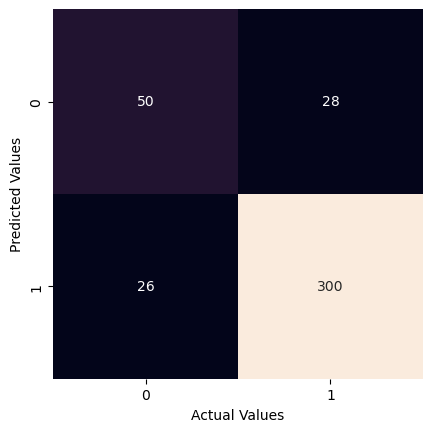

In [ ]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [ ]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.9447852760736196

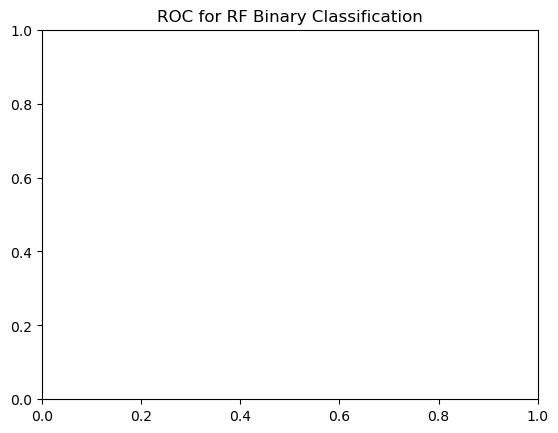

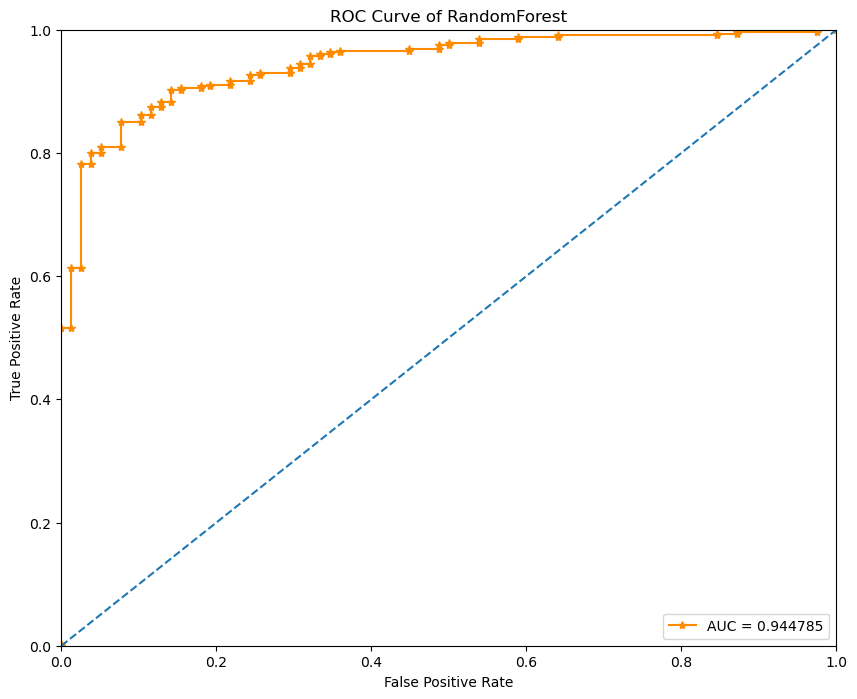

In [ ]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of RandomForest')
plt.show()

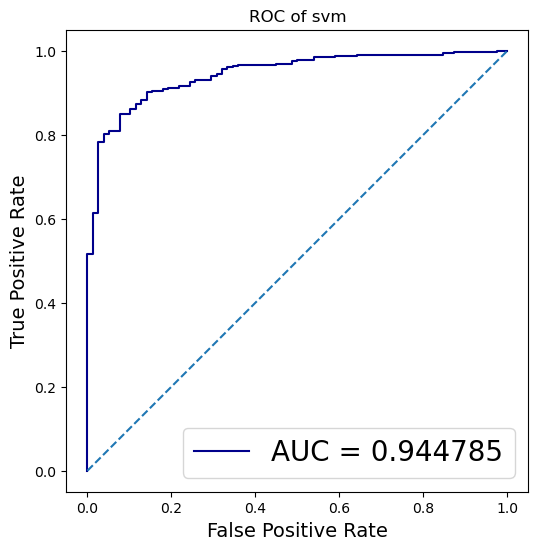

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of svm')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()


# SHAP

In [ ]:
# SHAP prerequisites check
if 'grid_search' not in locals():
    raise RuntimeError('grid_search is not defined. Run the model training cells before SHAP.')

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# --- 1) Prepare model and SHAP-ready data ---
best_estimator = grid_search.best_estimator_
print(f"Best estimator type: {type(best_estimator).__name__}")

# Recover feature names with priority:
# 1) Saved names before scaling, 2) DataFrame columns, 3) best_genes, 4) fallback labels
if 'gene_names_selected' in locals() and len(gene_names_selected) == np.asarray(X_train).shape[1]:
    feature_names = list(gene_names_selected)
elif isinstance(X_train, pd.DataFrame):
    feature_names = X_train.columns.tolist()
elif 'best_genes' in locals() and len(best_genes) >= np.asarray(X_train).shape[1]:
    feature_names = list(best_genes[:np.asarray(X_train).shape[1]])
else:
    feature_names = [f"Gene_{i}" for i in range(np.asarray(X_train).shape[1])]

X_train_shap = pd.DataFrame(np.asarray(X_train), columns=feature_names)
X_test_shap = pd.DataFrame(np.asarray(X_test), columns=feature_names)

# Use a subset for speed/stability with KernelExplainer
n_background = min(100, len(X_train_shap))
n_explain = min(80, len(X_test_shap))
background = shap.sample(X_train_shap, n_background, random_state=42)
X_explain = shap.sample(X_test_shap, n_explain, random_state=42)

# --- 2) Build SHAP explainer ---
# For SVC with non-linear kernels, KernelExplainer is the most robust choice.
def predict_pos_class(data):
    return best_estimator.predict_proba(data)[:, 1]

explainer = shap.KernelExplainer(predict_pos_class, background)
print("Calculating SHAP values... (this can take a while)")
shap_values = explainer.shap_values(X_explain, nsamples=200)

# Handle SHAP output shape across versions
if isinstance(shap_values, list):
    # Older SHAP can return [class0, class1]
    shap_matrix = np.asarray(shap_values[1])
else:
    shap_matrix = np.asarray(shap_values)
    if shap_matrix.ndim == 3:
        # (samples, features, classes) -> positive class
        shap_matrix = shap_matrix[:, :, 1]

print("SHAP matrix shape:", shap_matrix.shape)

Best estimator type: CatBoostClassifier
Calculating SHAP values... (this can take a while)


  0%|          | 0/80 [00:00<?, ?it/s]

SHAP matrix shape: (80, 79)


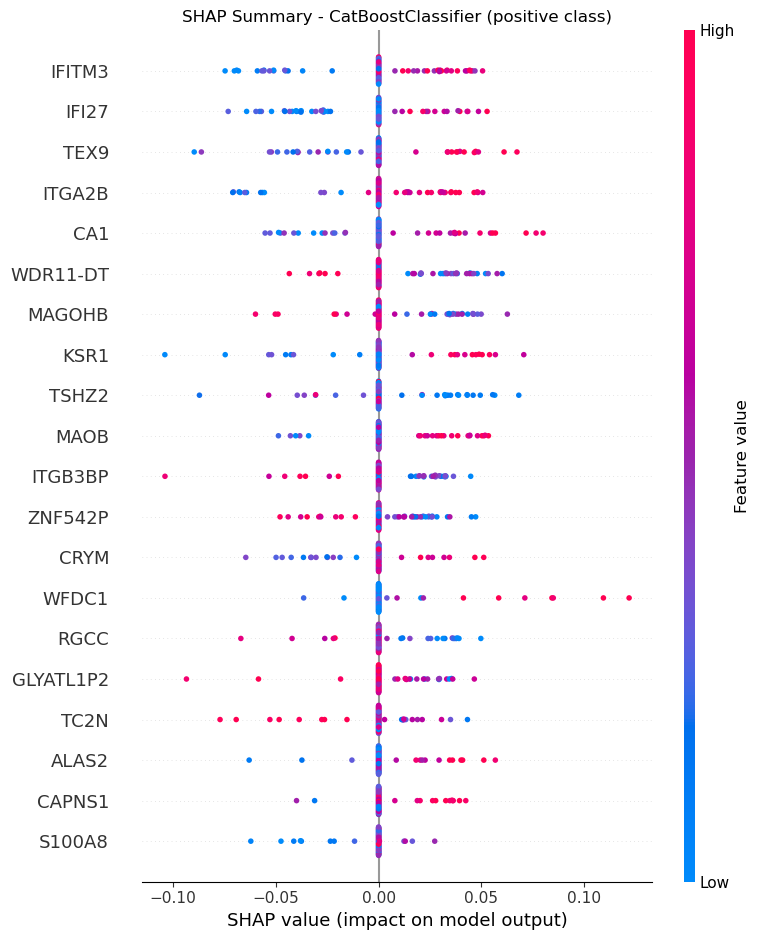

Top 10 Gene Biomarkers:
        Gene  SHAP_Abs_Mean
4     IFITM3       0.020106
17     IFI27       0.018375
27      TEX9       0.016280
3     ITGA2B       0.016213
8        CA1       0.015891
1   WDR11-DT       0.014457
0     MAGOHB       0.013412
56      KSR1       0.012658
76     TSHZ2       0.012413
12      MAOB       0.011218


In [ ]:
# --- 3) Plot SHAP summary ---
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_matrix,
    features=X_explain,
    feature_names=feature_names,
    show=False
)
plt.title(f"SHAP Summary - {type(best_estimator).__name__} (positive class)")
plt.tight_layout()
plot_name = f"shap_summary_{type(best_estimator).__name__}.png"
# plt.savefig(plot_name, bbox_inches='tight', dpi=300)
plt.show()

# --- 4) Export ranked biomarkers ---
mean_abs_shap = np.abs(shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    'Gene': feature_names,
    'SHAP_Abs_Mean': mean_abs_shap
}).sort_values(by='SHAP_Abs_Mean', ascending=False)

print("Top 10 Gene Biomarkers:")
print(importance_df.head(10))


In [ ]:

importance_df.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\SHAP\SHAP_CB.csv", index=False)
print(f"Saved SHAP plot to: {plot_name}")

Saved SHAP plot to: shap_summary_CatBoostClassifier.png
